# 04 · Tokenization

A cell is a vector of expression values with no natural order. Turning it
into a token sequence means choosing what to throw away. The repo has three
tokenizers (`src/data/tokenizers/`), and this notebook measures each choice:

| tokenizer | a token carries | discards |
|---|---|---|
| `continuous` | gene id + log-normalized value | nothing (the control) |
| `binned` | gene id + within-cell quantile bin | resolution inside a bin, absolute level |
| `rank` | gene id + rank position | magnitude entirely |

Sections:

1. One cell, three encodings
2. Bin occupancy and the true chance level for masked prediction
3. Sequence length and what truncation costs
4. Robustness to sequencing depth
5. How much biology survives tokenization
6. Sweeps over `n_bins` and `max_genes`
7. What the rank tokenizer's median normalization does
8. Masking and padding, as the model receives them

The data here is simulated deeper and wider than in the other notebooks
(about 800 genes detected per cell), so that truncation actually bites.

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display

from nbutils import (set_style, load_data, describe, pca, codes, probe_f1, label_bars,
                     SERIES, BLUE, ORANGE, AQUA, NEUTRAL, MUTED, SURFACE, INK, SEQ)
from src.core.registry import TOKENIZERS, SPLITTERS, autodiscover
from src.data.preprocessing import normalize_counts, GeneVocabulary
from src.data.datamodule import CellDataset, collate_cells
from src.eval.metrics import library_size_leakage, pcr_batch

autodiscover()
set_style()
TOK_COLORS = {"continuous": BLUE, "binned": ORANGE, "rank": AQUA}

In [2]:
DATA_PATH = None        # e.g. "/path/to/dataset.h5ad"
OBS_MAP   = None
RAW_LAYER = None

adata = load_data(DATA_PATH, OBS_MAP, RAW_LAYER, n_cells=2000, n_genes=6000,
                  library_size_median=20000, n_donors=12, seed=0)
IS_SYNTHETIC = bool(adata.uns.get("synthetic", False))

X = sp.csr_matrix(adata.X)
keep_genes = np.asarray((X > 0).sum(0)).ravel() >= 3
X = X[:, keep_genes].tocsr()
gene_names = adata.var_names.to_numpy()[keep_genes]
obs = adata.obs.reset_index(drop=True)
G = X.shape[1]

lognorm_sp, lib = normalize_counts(X)
L = np.asarray(lognorm_sp.todense())                 # dense log-normalized matrix
y = codes(obs["cell_type"])
batch = obs["batch_id"].astype(str).to_numpy()

split = SPLITTERS.build({"name": "donor_held_out", "val": 0.1, "test": 0.3, "seed": 0}).split(obs)
tr, te = np.concatenate([split["train"], split["val"]]), split["test"]
pd.DataFrame([describe(X, "after gene QC")]).set_index("stage")

,cells,genes,sparsity_%,median_depth,median_genes_per_cell
stage,,,,,
after gene QC,2000,4371,81.3,19770.0,809


Two helpers used throughout. `tokenize` runs a tokenizer over rows.
`decode` writes token values back into a cell × gene matrix, with zeros
wherever a gene produced no token. Decoding is what lets the same probe be
applied to every tokenization: it shows what a model *could* recover from
the tokens, before any learning.

In [3]:
GENE_IDX = np.arange(G)

def make(name, **kw):
    tok = TOKENIZERS.build({"name": name, **kw})
    if hasattr(tok, "fit"):
        tok.fit(lognorm_sp[tr])              # corpus statistics from training cells only
    return tok

def tokenize(tok, M):
    return [tok(row, GENE_IDX) for row in M]

def decode(tokens):
    out = np.zeros((len(tokens), G), dtype=np.float32)
    for i, t in enumerate(tokens):
        out[i, t["gene_ids"]] = t["values"]
    return out

MAX_GENES, N_BINS = 512, 51
toks = {
    "continuous": make("continuous", max_genes=MAX_GENES),
    "binned": make("binned", n_bins=N_BINS, max_genes=MAX_GENES),
    "rank": make("rank", max_genes=MAX_GENES),
}

## 1 · One cell, three encodings

The table lists one cell's most expressed genes with the value each
tokenizer assigns. `NaN` means the gene did not make it into that
tokenizer's sequence.

In [4]:
CELL = int(te[0])
row = L[CELL]
enc = {name: tok(row, GENE_IDX) for name, tok in toks.items()}

top = np.argsort(-row)[:12]
table = pd.DataFrame({"gene": gene_names[top], "raw UMIs": np.asarray(X[CELL, top].todense()).ravel().astype(int),
                      "log-normalized": row[top].round(2)})
for name, e in enc.items():
    lookup = dict(zip(e["gene_ids"], e["values"]))
    table[f"{name} token"] = [lookup.get(g, np.nan) for g in top]
print(f"cell {CELL}: {int((row > 0).sum())} genes detected; sequence lengths -> "
      + ", ".join(f"{k}: {len(v['gene_ids'])}" for k, v in enc.items()))
table.round(3)

cell 0: 984 genes detected; sequence lengths -> continuous: 512, binned: 512, rank: 512


,gene,raw UMIs,log-normalized,continuous token,binned token,rank token
0,GENE03801,2844,6.87,6.866,51.0,0.350
1,GENE05427,2057,6.54,6.543,51.0,0.307
2,GENE05912,1204,6.01,6.008,51.0,0.109
3,GENE00219,1184,5.99,5.991,51.0,0.332
4,GENE01051,1078,5.90,5.898,51.0,0.391
5,GENE05420,1003,5.83,5.826,51.0,0.236
6,GENE01094,699,5.47,5.466,51.0,0.475
7,GENE05634,682,5.44,5.442,51.0,0.588
8,GENE00270,615,5.34,5.339,51.0,0.428
9,GENE03252,581,5.28,5.282,51.0,0.643


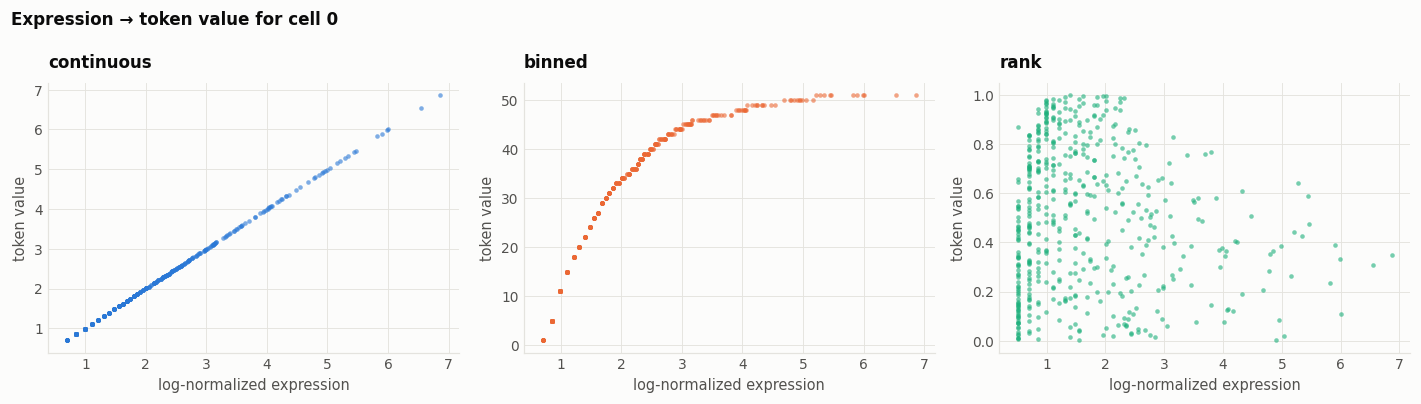

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.7))
for a, (name, e) in zip(ax, enc.items()):
    a.scatter(row[e["gene_ids"]], e["values"], s=9, color=TOK_COLORS[name], alpha=0.6, linewidths=0)
    a.set(title=name, xlabel="log-normalized expression", ylabel="token value")
fig.suptitle(f"Expression → token value for cell {CELL}", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

**Reading it.** `continuous` is the identity. `binned` is a staircase: each
flat step is a set of genes that now share one value, which is where
resolution is lost. `rank` is monotone only loosely, because genes are
ordered by expression *relative to each gene's typical level in the training
corpus*, not by raw expression (section 7).

## 2 · Bin occupancy and the true chance level

Bins are equal-frequency **within a cell**, and tied values share a bin.
How even the bins end up depends on how many ties a cell has, which depends
on depth: a shallow cell is mostly genes with one or two UMIs, and all of
those collapse into a few bins.

This matters for reading training curves. Masked-bin accuracy should be
compared with the accuracy of always guessing the most common bin, not with
`1 / n_bins`. The two panels show the same cells at full depth and thinned
to a tenth of it.

full depth             bins used: 51/51 | non-zero entries equal to 1 UMI: 25% | 1/n_bins = 0.020 | majority-bin floor = 0.028
thinned to 10% depth   bins used: 42/51 | non-zero entries equal to 1 UMI: 47% | 1/n_bins = 0.020 | majority-bin floor = 0.159


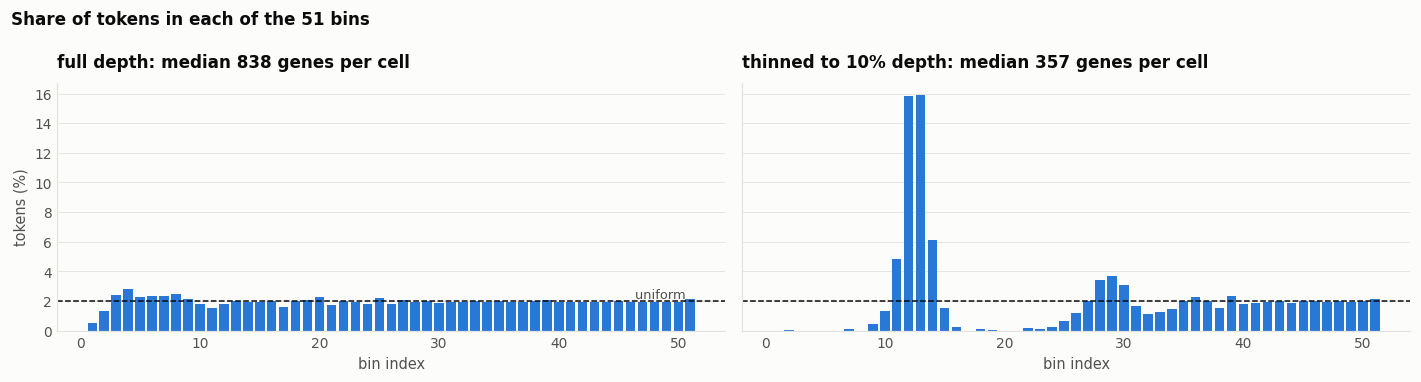

In [6]:
sample = te[:300]
rng0 = np.random.default_rng(1)

def thin_counts(Xc, p, rng):
    Y = Xc.copy()
    Y.data = rng.binomial(Y.data.astype(np.int64), p).astype(np.float32)
    Y.eliminate_zeros()
    return Y

views = {"full depth": X[sample], "thinned to 10% depth": thin_counts(X[sample], 0.1, rng0)}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for a, (label, Xv) in zip(ax, views.items()):
    Lv = np.asarray(normalize_counts(Xv)[0].todense())
    bins_v = np.concatenate([t["value_bins"] for t in tokenize(toks["binned"], Lv)])
    occ = np.bincount(bins_v, minlength=N_BINS + 1)[1:] / bins_v.size
    a.bar(np.arange(1, N_BINS + 1), 100 * occ, color=BLUE, width=0.8)
    a.axhline(100 / N_BINS, color=INK, linestyle="--", linewidth=1)
    a.set(title=f"{label}: median {int(np.median(np.diff(Xv.indptr)))} genes per cell", xlabel="bin index")
    a.grid(axis="x", visible=False)
    ones = np.mean(Xv.data == 1)
    print(f"{label:22s} bins used: {(occ > 0).sum():2d}/{N_BINS} | non-zero entries equal to 1 UMI: {ones:.0%} | "
          f"1/n_bins = {1 / N_BINS:.3f} | majority-bin floor = {occ.max():.3f}")
ax[0].set_ylabel("tokens (%)")
ax[0].text(N_BINS, 100 / N_BINS, "uniform ", va="bottom", ha="right", fontsize=8.5, color=MUTED)
fig.suptitle(f"Share of tokens in each of the {N_BINS} bins", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()

## 3 · Sequence length and what truncation costs

Attention cost grows with the square of sequence length, so every tokenizer
caps a cell at `max_genes` tokens, keeping the most expressed genes. The
panels show what that cap removes: detected genes, and molecules.

,cells truncated (%),detected genes kept (%),UMIs kept (%)
max_genes,,,
32,100.0,3.8,62.3
64,100.0,7.6,74.1
128,100.0,15.3,84.1
256,100.0,30.5,92.4
512,97.6,61.1,98.0
1024,11.3,100.0,100.0
2048,0.0,100.0,100.0


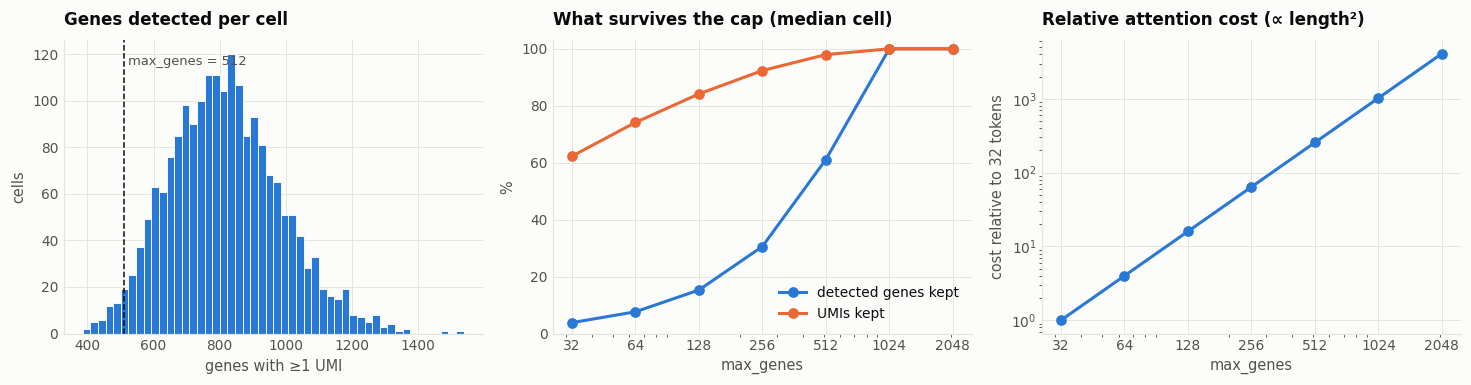

In [7]:
detected = np.diff(X.indptr)
caps = [32, 64, 128, 256, 512, 1024, 2048]
dense_counts = np.asarray(X[sample].todense())
sorted_counts = -np.sort(-dense_counts, axis=1)
umi_share = [np.median(sorted_counts[:, :c].sum(1) / sorted_counts.sum(1)) for c in caps]
gene_share = [np.median(np.minimum(detected[sample], c) / detected[sample]) for c in caps]
truncated = [(detected > c).mean() for c in caps]

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.6))
ax[0].hist(detected, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax[0].axvline(MAX_GENES, color=INK, linestyle="--", linewidth=1)
ax[0].text(MAX_GENES, ax[0].get_ylim()[1] * 0.95, f" max_genes = {MAX_GENES}", fontsize=8.5, color=MUTED, va="top")
ax[0].set(title="Genes detected per cell", xlabel="genes with ≥1 UMI", ylabel="cells")
ax[1].plot(caps, 100 * np.array(gene_share), marker="o", color=BLUE, label="detected genes kept")
ax[1].plot(caps, 100 * np.array(umi_share), marker="o", color=ORANGE, label="UMIs kept")
ax[1].set(title="What survives the cap (median cell)", xlabel="max_genes", ylabel="%", xscale="log", ylim=(0, 103))
ax[1].set_xticks(caps); ax[1].set_xticklabels(caps)
ax[1].legend(loc="lower right")
ax[2].plot(caps, [(c / caps[0]) ** 2 for c in caps], marker="o", color=BLUE)
ax[2].set(title="Relative attention cost (∝ length²)", xlabel="max_genes", ylabel=f"cost relative to {caps[0]} tokens",
          xscale="log", yscale="log")
ax[2].set_xticks(caps); ax[2].set_xticklabels(caps)
fig.tight_layout()

pd.DataFrame({"cells truncated (%)": 100 * np.array(truncated), "detected genes kept (%)": 100 * np.array(gene_share),
              "UMIs kept (%)": 100 * np.array(umi_share, dtype=float)}, index=pd.Index(caps, name="max_genes")).round(1)

**Reading it.** Molecules are concentrated in few genes, so a short sequence
keeps most UMIs while dropping most *genes*. The dropped genes are the
low-count tail, which is where rare cell-type markers tend to sit. Section 6
measures whether that tail matters for a probe.

## 4 · Robustness to sequencing depth

The same cell sequenced more shallowly should ideally get the same tokens.
Here each test cell's counts are thinned at random to a fraction of their
depth, re-normalized and re-tokenized, then compared with the full-depth
encoding:

- **gene-set overlap** – Jaccard index between the two token gene sets
- **value shift** – mean absolute change in token value over shared genes,
  as a fraction of that tokenizer's value range

,continuous overlap,binned overlap,rank overlap,continuous shift,binned shift,rank shift
depth fraction,,,,,,
1.00,1.000,1.000,1.000,0.000,0.000,0.000
0.50,0.793,0.793,0.717,0.027,0.072,0.136
0.25,0.695,0.695,0.609,0.042,0.107,0.162
0.10,0.558,0.558,0.478,0.067,0.156,0.167
0.05,0.428,0.428,0.366,0.093,0.201,0.167


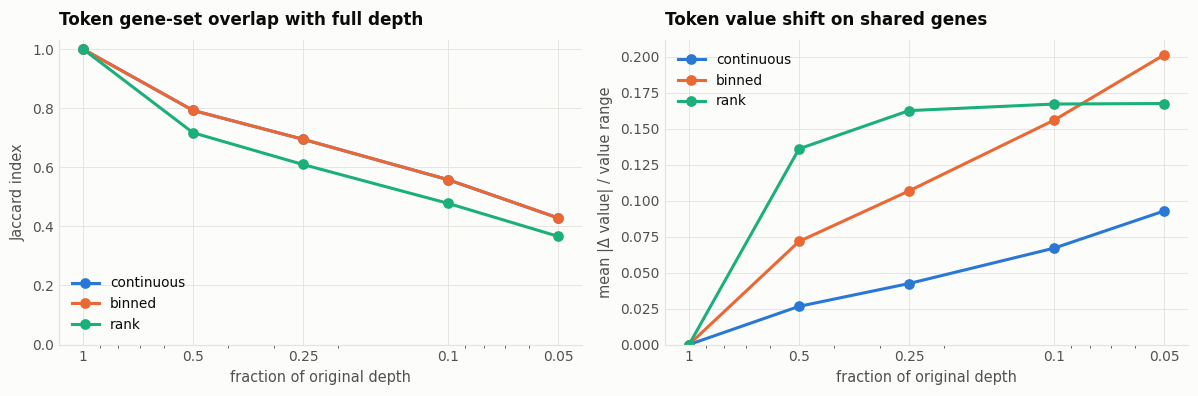

In [8]:
rng = np.random.default_rng(0)
cells = te[:200]
thin = lambda Xc, p: thin_counts(Xc, p, rng)

value_range = {"continuous": None, "binned": float(N_BINS), "rank": 1.0}   # None -> per-cell max
full = {name: tokenize(tok, L[cells]) for name, tok in toks.items()}
fractions = [1.0, 0.5, 0.25, 0.1, 0.05]
overlap = {k: [] for k in toks}
shift = {k: [] for k in toks}
for p in fractions:
    Lp = np.asarray(normalize_counts(thin(X[cells], p))[0].todense())
    for name, tok in toks.items():
        jac, sh = [], []
        for t_full, t_thin in zip(full[name], tokenize(tok, Lp)):
            a, b = dict(zip(t_full["gene_ids"], t_full["values"])), dict(zip(t_thin["gene_ids"], t_thin["values"]))
            shared = a.keys() & b.keys()
            union = a.keys() | b.keys()
            if not union:
                continue
            jac.append(len(shared) / len(union))
            if shared:
                scale = value_range[name] or max(a.values())
                sh.append(np.mean([abs(a[g] - b[g]) for g in shared]) / scale)
        overlap[name].append(np.mean(jac)); shift[name].append(np.mean(sh))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
for name in toks:
    ax[0].plot(fractions, overlap[name], marker="o", color=TOK_COLORS[name], label=name)
    ax[1].plot(fractions, shift[name], marker="o", color=TOK_COLORS[name], label=name)
ax[0].set(title="Token gene-set overlap with full depth", xlabel="fraction of original depth",
          ylabel="Jaccard index", xscale="log", ylim=(0, 1.03))
ax[1].set(title="Token value shift on shared genes", xlabel="fraction of original depth",
          ylabel="mean |Δ value| / value range", xscale="log", ylim=(0, None))
for a in ax:
    a.set_xticks(fractions); a.set_xticklabels([f"{f:g}" for f in fractions]); a.invert_xaxis()
ax[0].legend(loc="lower left"); ax[1].legend(loc="upper left")
fig.tight_layout()
pd.DataFrame({f"{k} overlap": overlap[k] for k in toks} | {f"{k} shift": shift[k] for k in toks},
             index=pd.Index(fractions, name="depth fraction")).round(3)

**Reading it.** Gene-set overlap falls for every tokenizer, because genes
that drop to zero cannot produce a token; no encoding of values can fix
that. (`continuous` and `binned` keep the same genes, so their overlap lines
coincide.) The value panel is where the tokenizers differ: a value that moves
with depth is a value that encodes depth.

Note the difference between two properties. Bins and ranks are invariant to
*rescaling* a cell (multiplying every count by a constant). They are not
invariant to *losing depth*, because thinning changes which genes are
detected, and quantile bins and rank positions are computed relative to the
detected set.

## 5 · How much biology survives tokenization

Decode each tokenization back to a cell × gene matrix, fit a PCA on the
training donors, and score held-out donors three ways:

- **cell-type probe** – what is kept (higher is better)
- **depth R²** – how much of the embedding sequencing depth explains
- **batch (PCR)** – how much of it batch explains

The first bar is the untokenized log-normalized matrix, for reference.

,cell-type probe F1,depth R²,batch (PCR)
log-normalized (no tokenizer),0.899,0.745,0.567
continuous,0.893,0.630,0.563
binned,0.848,0.847,0.537
rank,0.856,0.453,0.578


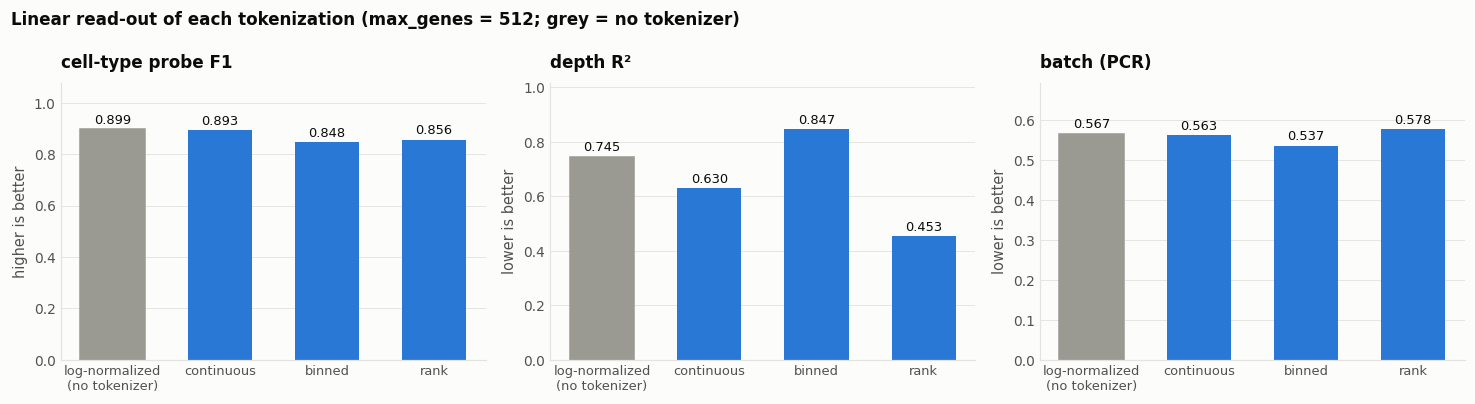

In [9]:
def evaluate(M):
    Ztr, Zte = pca(M[tr], M[te], k=30)
    return {"cell-type probe F1": probe_f1(Ztr, y[tr], Zte, y[te]),
            "depth R²": library_size_leakage(Zte, lib[te]),
            "batch (PCR)": pcr_batch(Zte, batch[te])}

decoded = {name: decode(tokenize(tok, L)) for name, tok in toks.items()}
info = pd.DataFrame({"log-normalized\n(no tokenizer)": evaluate(L),
                     **{name: evaluate(M) for name, M in decoded.items()}}).T

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.7))
for a, col, note in zip(ax, info.columns, ["higher is better", "lower is better", "lower is better"]):
    bars = a.bar(info.index, info[col], color=BLUE, width=0.6)
    bars[0].set_color(NEUTRAL)
    a.set(title=col, ylabel=note, ylim=(0, max(1.0 if "F1" in col else 0, info[col].max() * 1.2)))
    a.grid(axis="x", visible=False)
    a.tick_params(axis="x", labelsize=8.5)
    label_bars(a, bars, fmt="{:.3f}")
fig.suptitle(f"Linear read-out of each tokenization (max_genes = {MAX_GENES}; grey = no tokenizer)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
info.rename(index=lambda s: s.replace("\n", " ")).round(3)

This is a linear read-out, so it is a floor on what a trained model can
extract, not a prediction of model quality. Its use is comparative: a
tokenizer that loses cell-type signal here has discarded it for good, and a
tokenizer with high depth R² is handing the model a shortcut.

## 6 · Sweeps

**`n_bins`** – how coarse can the binning get before the probe notices?
**`max_genes`** – how short can the sequence get?

,cell-type probe F1,depth R²,batch (PCR)
n_bins,,,
2,0.772,0.846,0.505
3,0.829,0.839,0.526
5,0.842,0.829,0.529
11,0.847,0.835,0.534
21,0.842,0.842,0.536
51,0.848,0.847,0.537
101,0.847,0.846,0.537


,continuous,binned,rank
max_genes,,,
32,0.593,0.686,0.635
64,0.573,0.704,0.740
128,0.594,0.670,0.822
256,0.837,0.797,0.857
512,0.893,0.848,0.856
1024,0.897,0.849,0.843


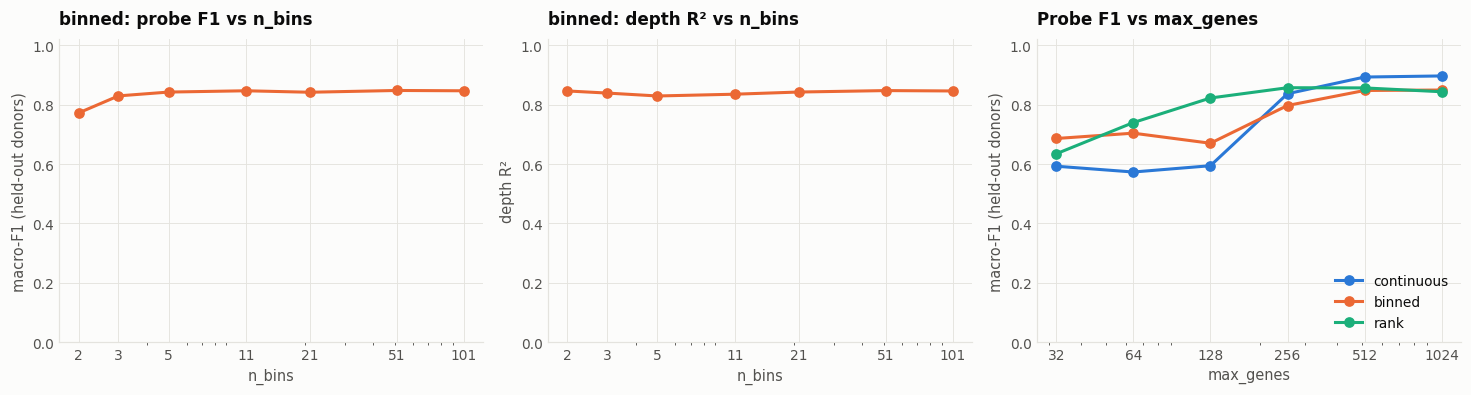

In [10]:
bin_grid = [2, 3, 5, 11, 21, 51, 101]
bin_res = [evaluate(decode(tokenize(make("binned", n_bins=b, max_genes=MAX_GENES), L))) for b in bin_grid]

cap_grid = [32, 64, 128, 256, 512, 1024]
cap_res = {name: [evaluate(decode(tokenize(make(name, max_genes=c, **({"n_bins": N_BINS} if name == "binned" else {})), L)))
                  ["cell-type probe F1"] for c in cap_grid] for name in toks}

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.7))
ax[0].plot(bin_grid, [r["cell-type probe F1"] for r in bin_res], marker="o", color=ORANGE)
ax[0].set(title="binned: probe F1 vs n_bins", xlabel="n_bins", ylabel="macro-F1 (held-out donors)", xscale="log", ylim=(0, 1.02))
ax[0].set_xticks(bin_grid); ax[0].set_xticklabels(bin_grid)
ax[1].plot(bin_grid, [r["depth R²"] for r in bin_res], marker="o", color=ORANGE)
ax[1].set(title="binned: depth R² vs n_bins", xlabel="n_bins", ylabel="depth R²", xscale="log", ylim=(0, 1.02))
ax[1].set_xticks(bin_grid); ax[1].set_xticklabels(bin_grid)
for name, vals in cap_res.items():
    ax[2].plot(cap_grid, vals, marker="o", color=TOK_COLORS[name], label=name)
ax[2].set(title="Probe F1 vs max_genes", xlabel="max_genes", ylabel="macro-F1 (held-out donors)", xscale="log", ylim=(0, 1.02))
ax[2].set_xticks(cap_grid); ax[2].set_xticklabels(cap_grid)
ax[2].legend(loc="lower right")
fig.tight_layout()

display(pd.DataFrame(bin_res, index=pd.Index(bin_grid, name="n_bins")).round(3))
pd.DataFrame(cap_res, index=pd.Index(cap_grid, name="max_genes")).round(3)

## 7 · The rank tokenizer's median normalization

Before ranking, the rank tokenizer divides each gene by its median non-zero
expression in the training corpus. A gene that is always high (housekeeping)
is pushed down the order; a gene that is usually low but high *in this cell*
is pulled up. The chart shows the average rank position of genes grouped by
how abundant they are overall, with and without that normalization.

genes shared between the two 'top 100 earliest' lists: 0 / 100
  program genes among the 100 earliest, ranked by raw expression: 12%  (all genes: 9%)
  program genes among the 100 earliest, ranked after median normalization: 7%  (all genes: 9%)


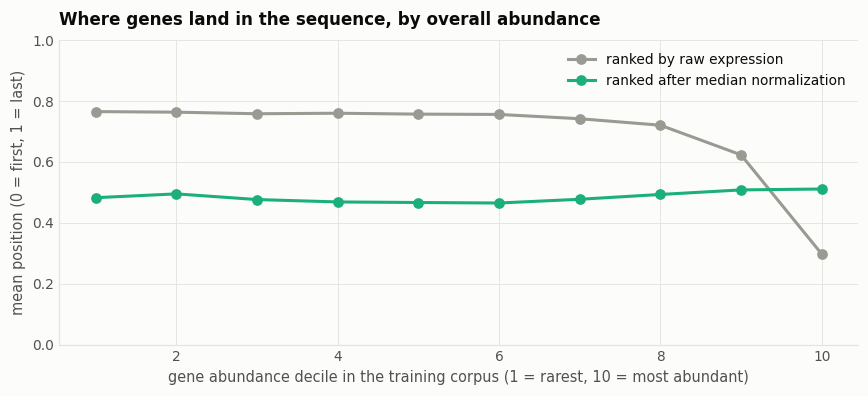

In [11]:
unfitted = TOKENIZERS.build({"name": "rank", "max_genes": G})        # no corpus statistics
fitted = make("rank", max_genes=G)

def mean_position(tok):
    total, count = np.zeros(G), np.zeros(G)
    for t in tokenize(tok, L[sample]):
        n = len(t["gene_ids"])
        total[t["gene_ids"]] += np.arange(n) / max(n - 1, 1)        # 0 = first in sequence, 1 = last
        count[t["gene_ids"]] += 1
    return np.divide(total, count, out=np.full(G, np.nan), where=count > 0)

pos = {"ranked by raw expression": mean_position(unfitted), "ranked after median normalization": mean_position(fitted)}
corpus_mean = np.asarray(lognorm_sp[tr].mean(0)).ravel()
seen = ~np.isnan(pos["ranked by raw expression"])
decile = pd.qcut(corpus_mean[seen], 10, labels=False, duplicates="drop")

fig, ax = plt.subplots(figsize=(8, 3.7))
for (name, p), color in zip(pos.items(), [NEUTRAL, AQUA]):
    ax.plot(range(1, decile.max() + 2), pd.Series(p[seen]).groupby(decile).mean().values, marker="o", color=color, label=name)
ax.set(title="Where genes land in the sequence, by overall abundance",
       xlabel="gene abundance decile in the training corpus (1 = rarest, 10 = most abundant)",
       ylabel="mean position (0 = first, 1 = last)", ylim=(0, 1))
ax.legend(loc="upper right")
fig.tight_layout()

first = {k: set(np.argsort(np.nan_to_num(v, nan=2))[:100]) for k, v in pos.items()}
print(f"genes shared between the two 'top 100 earliest' lists: {len(set.intersection(*first.values()))} / 100")
if IS_SYNTHETIC and "is_marker" in adata.var:
    marker = adata.var["is_marker"].to_numpy()[keep_genes]
    for k, v in first.items():
        print(f"  program genes among the 100 earliest, {k}: {marker[list(v)].mean():.0%}  (all genes: {marker.mean():.0%})")

The flatter the line, the less a gene's position is decided by its overall
abundance and the more by this cell's deviation from typical. Because a
short sequence keeps only the earliest positions, this normalization also
changes *which genes survive truncation*.

## 8 · Masking and padding, as the model receives them

`CellDataset` applies the tokenizer and hides a fraction of token values;
`collate_cells` pads a list of cells to a rectangle. The picture shows one
batch: every row is a cell, every column a token position.

CellBatch(B=32, L=1473, bins=y, masked=y, targets=['cell_type', 'value_bins', 'values'], meta=['index'])
padding: 44.8% of the tensor | masked: 15.0% of real tokens
masked inputs carry bin 0: True | gene ids stay visible: True | targets keep the true bin: True


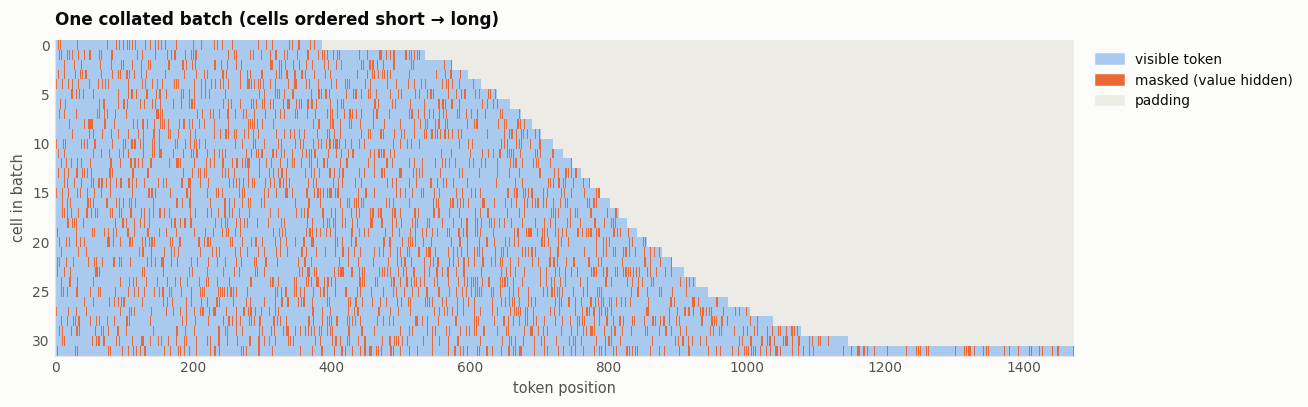

In [12]:
vocab = GeneVocabulary(gene_names)
label_maps = {"cell_type": {v: i for i, v in enumerate(sorted(obs["cell_type"].astype(str).unique()))}}
wide = make("binned", n_bins=N_BINS, max_genes=2048)          # long cap, so true lengths show
ds = CellDataset(counts=X[tr], normalized=lognorm_sp[tr], obs=obs.iloc[tr], tokenizer=wide,
                 vocab=vocab, label_maps=label_maps, mask_ratio=0.15, seed=0, train=True)
order = np.argsort(np.diff(X[tr].indptr))[np.linspace(0, len(tr) - 1, 32).astype(int)]   # short to long cells
cb = collate_cells([ds[int(i)] for i in order])
print(cb)

state = np.zeros(cb.pad_mask.shape, dtype=int)             # 0 = padding
state[cb.pad_mask.numpy()] = 1                             # 1 = visible token
state[cb.mask_positions.numpy()] = 2                       # 2 = masked token
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.imshow(state, aspect="auto", cmap=ListedColormap(["#ecebe6", "#a9c9ef", ORANGE]), interpolation="nearest")
ax.set(title="One collated batch (cells ordered short → long)", xlabel="token position", ylabel="cell in batch")
ax.grid(False)
ax.legend(handles=[Patch(color="#a9c9ef", label="visible token"), Patch(color=ORANGE, label="masked (value hidden)"),
                   Patch(color="#ecebe6", label="padding")], loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()

real = cb.pad_mask.sum().item()
print(f"padding: {1 - real / cb.pad_mask.numel():.1%} of the tensor | "
      f"masked: {cb.mask_positions.sum().item() / real:.1%} of real tokens")
m = cb.mask_positions
print("masked inputs carry bin 0:", bool((cb.value_bins[m] == 0).all()),
      "| gene ids stay visible:", bool((cb.gene_ids[m] > 0).all()),
      "| targets keep the true bin:", bool((cb.targets['value_bins'][m] > 0).all()))

A masked token keeps its gene id and loses its value, so the task is "given
which genes are present and the levels of the others, what is this gene's
level?". Padding is wasted computation: a batch is as long as its longest
cell, so mixing short and long cells (as here) pays for the difference.
Batching cells of similar length, or a lower `max_genes`, reduces it.

Training masks are redrawn every epoch, evaluation masks are fixed:

In [13]:
ev = CellDataset(counts=X[te], normalized=lognorm_sp[te], obs=obs.iloc[te], tokenizer=wide,
                 vocab=vocab, label_maps=label_maps, mask_ratio=0.15, seed=0, train=False)
def masks(dataset, epoch):
    dataset.set_epoch(epoch)
    return dataset[0]["mask_positions"]
same_train = np.mean(masks(ds, 0) == masks(ds, 1))
same_eval = np.mean(masks(ev, 0) == masks(ev, 1))
ds.set_epoch(0); ev.set_epoch(0)
print(f"training cell, epoch 0 vs 1: {same_train:.0%} of positions have the same mask state (re-drawn)")
print(f"evaluation cell, epoch 0 vs 1: {same_eval:.0%} (fixed, so validation loss is comparable across epochs)")

training cell, epoch 0 vs 1: 75% of positions have the same mask state (re-drawn)
evaluation cell, epoch 0 vs 1: 100% (fixed, so validation loss is comparable across epochs)


## What to carry forward

- Compare masked-bin accuracy with the **majority-bin floor** for your
  data's depth (section 2), never with `1 / n_bins`.
- Bins and ranks survive rescaling, not real depth loss.
- `max_genes` trades detected genes for quadratic compute. Check section 6
  on your data before paying for a longer sequence.
- A tokenizer whose values move with depth gives the model a depth
  shortcut. Sections 4 and 5 measure it from two directions.
- The rank tokenizer's corpus medians are fitted on training cells only,
  and they decide which genes survive truncation.
- To train with a different tokenizer:
  `python run.py +experiment=pretrain_synthetic model=continuous data/tokenizer=rank`